# Применение NoisyNets в обучении с подкреплением

**Курсовая работа по МГМО. Завершённая экспериментальная серия.**

Горбунов Иван Олегович, ИУ6-74б. Руководитель: Кудрявцев Сергей Александрович.

Сравниваются DQN с ε-жадным исследованием и NoisyNet-DQN на CartPole-v1
и Acrobot-v1. Для Acrobot дополнительно проверяются масштаб, обучаемость
и частота обновления параметрического шума. Здесь доступны настройки,
результаты каждого запуска, графики и повторная проверка сохранённых моделей.

Пилотная серия на 30 000 шагов находится в `01_pilot_study.ipynb`.
Она использовалась для проверки реализации и не включена в таблицы ниже.

## 1. Вопрос исследования и протокол

Основной вопрос: как замена ε-жадного выбора действий обучаемым
параметрическим шумом влияет на награду и ход обучения при фиксированном
числе взаимодействий со средой? Основные сравнения — DQN и NoisyNet-DQN
с σ₀ = 0,5 отдельно в каждой среде. Абляции на Acrobot имеют исследовательский
характер; по ним не выбирается задним числом основной вариант.

План расширенной серии сохранён в `configs/final_study.json` до её запуска.
Использованы 10 seed обучения, 100–109. Модели оцениваются каждые 10 % бюджета
на 10 эпизодах с seed 30000–30009. Последняя модель каждого запуска отдельно
проверяется на 30 эпизодах с seed 40000–40029. Итоговые эпизоды не используются
для выбора checkpoint или настройки гиперпараметров; сохраняется последняя модель.

В каждом сравнении повторения спарены по seed обучения. Совпадают начальные
средние веса и общие параметры алгоритма, но дальнейшие траектории, содержимое
replay buffer и случайные действия методов могут различаться.

In [1]:
import json
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

from noisynets.final_analysis import (
    LABELS, load_study, summarize_study, make_study_figures,
    verify_checkpoints,
)

ROOT = Path.cwd()
if not (ROOT / "configs/final_study.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "configs/final_study.json").exists(), "Запустите ноутбук из проекта"
RESULTS = ROOT / "results/final"
OUTPUT = ROOT / "results/final_analysis"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")
torch.set_num_threads(1)

runs, curves, manifest = load_study(RESULTS, ROOT / "configs/final_study.json")
summary = summarize_study(runs)
assert len(runs) == 80 and summary["total_training_steps"] == 11_000_000
print(f"Завершённых запусков: {len(runs)}; шагов обучения: {summary['total_training_steps']:,}")
display(pd.DataFrame({
    "Библиотека": ["torch", "gymnasium", "numpy", "pandas"],
    "Версия при выполнении ноутбука": [version(p) for p in ["torch", "gymnasium", "numpy", "pandas"]],
}))

Завершённых запусков: 80; шагов обучения: 11,000,000


,Библиотека,Версия при выполнении ноутбука
0,torch,2.15.0
1,gymnasium,1.4.0
2,numpy,2.5.4
3,pandas,3.1.1


In [2]:
settings = []
for environment in manifest["environments"]:
    c = environment["config"]
    settings.append({
        "Среда": c["env"], "Шаги": c["steps"], "Скрытый слой": c["hidden"],
        "Шаг Adam": c["learning_rate"], "γ": c["gamma"],
        "Размер batch": c["batch_size"], "Replay": c["replay_capacity"],
        "Разминка": c["learning_starts"], "Частота update": c["train_frequency"],
        "Синхронизация target": c["target_interval"],
        "Спад ε, шаги": c["epsilon_decay_steps"], "Условия": len(environment["conditions"]),
    })
display(pd.DataFrame(settings).set_index("Среда"))
display(pd.DataFrame([
    {"Среда": env["key"], "Условие": condition["key"], **{
        key: value for key, value in condition.items() if key != "key"}}
    for env in manifest["environments"] for condition in env["conditions"]
]))

,Шаги,Скрытый слой,Шаг Adam,γ,Размер batch,Replay,Разминка,Частота update,Синхронизация target,"Спад ε, шаги",Условия
Среда,,,,,,,,,,,
CartPole-v1,100000,64,0.000,0.990,64,100000,2000,4,1000,50000,2
Acrobot-v1,150000,128,0.000,0.990,64,100000,2000,4,1000,75000,6


,Среда,Условие,algorithm,sigma0,noise_cadence
0,cartpole,dqn,dqn,0.500,action
1,cartpole,noisy,noisy,0.500,action
2,acrobot,dqn,dqn,0.500,action
3,acrobot,noisy,noisy,0.500,action
4,acrobot,noisy_sigma01,noisy,0.100,action
5,acrobot,noisy_sigma10,noisy,1.000,action
6,acrobot,noisy_fixed,noisy-fixed,0.500,action
7,acrobot,noisy_update,noisy,0.500,update


CartPole содержит четыре наблюдаемые координаты и два действия. Награда
составляет +1 за шаг, лимит — 500 шагов. В Acrobot шесть наблюдаемых величин
и три действия; требуется поднять конец двухзвенного маятника до заданной
высоты. Награда равна −1 на обычном переходе и 0 при достижении цели,
эпизод ограничен 500 шагами. Поэтому более высокая, менее отрицательная
награда Acrobot соответствует более быстрому достижению цели.
См. официальные описания [CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/)
и [Acrobot](https://gymnasium.farama.org/environments/classic_control/acrobot/).

Одинаковые оценочные старты уменьшают вариацию от начального состояния.
Это фиксированная небольшая выборка стартов, а не независимая оценка
по всем возможным состояниям среды.

## 2. Реализация алгоритмов

Q-сеть имеет два скрытых слоя с ReLU. DQN использует линейный спад ε
от 1 до 0,05, replay buffer, отдельную target-сеть и Huber loss.
TD-цель имеет вид

$$y=r+\gamma(1-\mathbb{1}_{\mathrm{terminated}})\max_a Q_{\bar\theta}(s',a).$$

Ограничение эпизода по времени (`truncated`) завершает сбор эпизода,
но не обнуляет будущую ценность в этой цели. Это соответствует
[рекомендации Gymnasium](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/).

У NoisyNet два последних линейных слоя заменены шумовыми, первый остаётся
обычным. Для одного слоя с p входами и q выходами:

$$y=(\mu_W+\sigma_W\odot\varepsilon_W)x+\mu_b+\sigma_b\odot\varepsilon_b,$$
$$f(z)=\operatorname{sign}(z)\sqrt{|z|},\quad z\sim\mathcal N(0,1),$$
$$\varepsilon_W=f(z_{out})f(z_{in})^T,\qquad\varepsilon_b=f(z_{out}).$$

Средние веса и масштабы шума обучаются градиентным методом. Инициализация:
σ_W = σ₀/√p, σ_b = σ₀/√q, μ равномерны на [−1/√p, 1/√p].
Такой масштаб смещений используется в [официальной реализации TorchRL](https://docs.pytorch.org/rl/stable/_modules/torchrl/modules/models/exploration.html).
Параметр σ не ограничен по знаку и не равен точному стандартному отклонению
возмущения. Матрица ε_W имеет ранг не более 1; обучаемая матрица σ_W ⊙ ε_W
в общем случае этого свойства не сохраняет.

Метод параметрического шума описан у
[Fortunato и соавторов, Noisy Networks for Exploration](https://arxiv.org/html/1706.10295v3).
Здесь исследуется адаптация к двум средам с векторными наблюдениями;
Atari-эксперимент исходной статьи не воспроизводится.

В основной версии шум поведения обновляется перед каждым действием.
При каждом шаге оптимизатора шум основной и target-сети обновляется
независимо; один шум используется для всего batch. В исходной статье
шум поведения обновлялся после оптимизации, выполняемой на каждом шаге
среды. В нашей реализации обновление параметров выполняется каждые четыре
шага среды, поэтому частота шума выделена в отдельную абляцию.

В `noisy_update` после начала обучения шум поведения сохраняется между
обновлениями параметров и пересэмплируется после update. До шага 2000
включительно во всех Noisy-вариантах действует одинаковая разминка
с новым шумом перед каждым действием. В `noisy_fixed` σ не обучается;
μ по-прежнему обучается. Условия с σ₀ = 0,1 и 1,0 меняют только начальный
масштаб. Для всех Noisy-вариантов ε-жадное исследование отключено.

Основная оценка использует жадные действия по средним весам μ.
Отдельно оценивается политика с шумом перед каждым действием, в том числе
для варианта `noisy_update`: это единое соглашение для сопоставления моделей.
Политики по μ и с шумом различаются; нелинейная сеть не удовлетворяет
в общем случае равенству Q(Eθ) = E Q(θ).

## 3. Метрики и способ агрегирования

Единица повторения — отдельное обучение с одним seed. Сначала для модели
усредняются награды 30 отложенных эпизодов, затем эти значения усредняются
по десяти seed. Стандартное отклонение в сводных таблицах характеризует
разброс между обученными моделями. Эпизоды одной модели не считаются
независимыми обучениями.

Дополнительно приводятся медиана и диапазон по seed, а также площадь под
валидационной кривой, делённая на число шагов обучения:

$$\operatorname{AUC}_{\mathrm{norm}}=\frac1T\int_0^T\bar R_{val}(t)\,dt.$$

Интеграл вычисляется методом трапеций, включая оценку до обучения.
Метрика сохраняет единицы награды и отражает весь ход обучения, но зависит
от частоты валидационных точек. AUC сопоставляется внутри одной среды.

Интервалы разности получены парным процентильным bootstrap: 20 000
перевыборок десяти seed, с сохранением пары методов. Seed bootstrap — 7241.
Интервалы описательные, без поправки на множественные сравнения. Пересечение
интервала с нулём не доказывает равенство методов, а непересечение само
по себе не устраняет ограничения малого числа повторений. Неопределённость
фиксированной выборки стартов отдельно не моделируется. О важности
интервальных оценок в deep RL см.
[Agarwal и соавторов](https://arxiv.org/abs/2108.13264).

In [3]:
# Все результаты по seed без отбора лучших запусков.
columns = ["environment", "condition", "seed", "final_mean", "final_episode_sd",
           "auc_mean", "stochastic_mean", "success_rate"]
display(runs[columns].rename(columns={
    "environment": "Среда", "condition": "Условие", "seed": "Seed",
    "final_mean": "Награда μ", "final_episode_sd": "SD эпизодов",
    "auc_mean": "AUC / T", "stochastic_mean": "Награда с шумом",
    "success_rate": "Доля достижения цели / лимита",
}).reset_index(drop=True))

,Среда,Условие,Seed,Награда μ,SD эпизодов,AUC / T,Награда с шумом,Доля достижения цели / лимита
0,acrobot,dqn,100,-176.933,153.035,-388.795,NaN,0.833
1,acrobot,dqn,101,-86.500,16.288,-307.990,NaN,1.000
2,acrobot,dqn,102,-500.000,0.000,-392.400,NaN,0.000
3,acrobot,dqn,103,-80.700,11.357,-426.335,NaN,1.000
4,acrobot,dqn,104,-89.800,20.147,-375.315,NaN,1.000
5,acrobot,dqn,105,-500.000,0.000,-448.120,NaN,0.000
6,acrobot,dqn,106,-77.933,9.255,-331.930,NaN,1.000
7,acrobot,dqn,107,-83.833,14.506,-292.725,NaN,1.000
8,acrobot,dqn,108,-140.133,133.977,-269.505,NaN,0.900
9,acrobot,dqn,109,-131.200,73.211,-410.395,NaN,0.967


In [4]:
condition_table = pd.DataFrame(summary["conditions"])
display(condition_table[["env_id", "label", "n_seeds", "final_mean", "final_seed_sd",
                         "final_seed_median", "final_min", "final_max", "auc_mean",
                         "auc_seed_sd", "success_rate"]].rename(columns={
    "env_id": "Среда", "label": "Условие", "n_seeds": "N",
    "final_mean": "Средняя награда", "final_seed_sd": "SD по seed",
    "final_seed_median": "Медиана", "final_min": "Минимум", "final_max": "Максимум",
    "auc_mean": "AUC / T", "auc_seed_sd": "SD AUC", "success_rate": "Доля цели / лимита",
}).reset_index(drop=True))

,Среда,Условие,N,Средняя награда,SD по seed,Медиана,Минимум,Максимум,AUC / T,SD AUC,Доля цели / лимита
0,Acrobot-v1,DQN,10,-186.703,168.238,-110.500,-500.000,-77.933,-364.351,60.404,0.770
1,Acrobot-v1,NoisyNet-DQN,10,-459.273,128.789,-500.000,-500.000,-92.733,-449.599,48.766,0.100
2,Acrobot-v1,Фиксированный σ,10,-500.000,0.000,-500.000,-500.000,-500.000,-491.501,18.705,0.000
3,Acrobot-v1,"σ₀ = 0,1",10,-428.950,133.614,-500.000,-500.000,-117.267,-439.891,46.324,0.183
4,Acrobot-v1,"σ₀ = 1,0",10,-404.997,164.874,-500.000,-500.000,-101.433,-453.698,33.070,0.240
5,Acrobot-v1,Шум между обновлениями,10,-431.750,145.942,-500.000,-500.000,-106.933,-421.428,42.577,0.173
6,CartPole-v1,DQN,10,139.883,51.072,117.683,102.233,260.967,182.815,29.774,0.000
7,CartPole-v1,NoisyNet-DQN,10,131.137,80.038,114.100,24.400,268.533,139.415,26.022,0.003


`Доля цели / лимита` для Acrobot — доля эпизодов с фактическим
`terminated=True`; для CartPole — доля эпизодов, дошедших до ограничения
времени (`truncated=True`). Значения вычислены по признакам среды,
сохранённым для каждого эпизода, а не по порогу суммарной награды.
Это разные по смыслу показатели для двух задач.

## 4. Основное сравнение DQN и NoisyNet-DQN

,Среда,Метрика,Noisy − DQN,Нижняя граница 95%,Верхняя граница 95%,Пар seed
0,acrobot,final_mean,-272.570,-400.074,-101.451,10
1,acrobot,auc_mean,-85.248,-133.834,-37.039,10
2,cartpole,final_mean,-8.747,-61.867,39.511,10
3,cartpole,auc_mean,-43.401,-63.536,-27.796,10


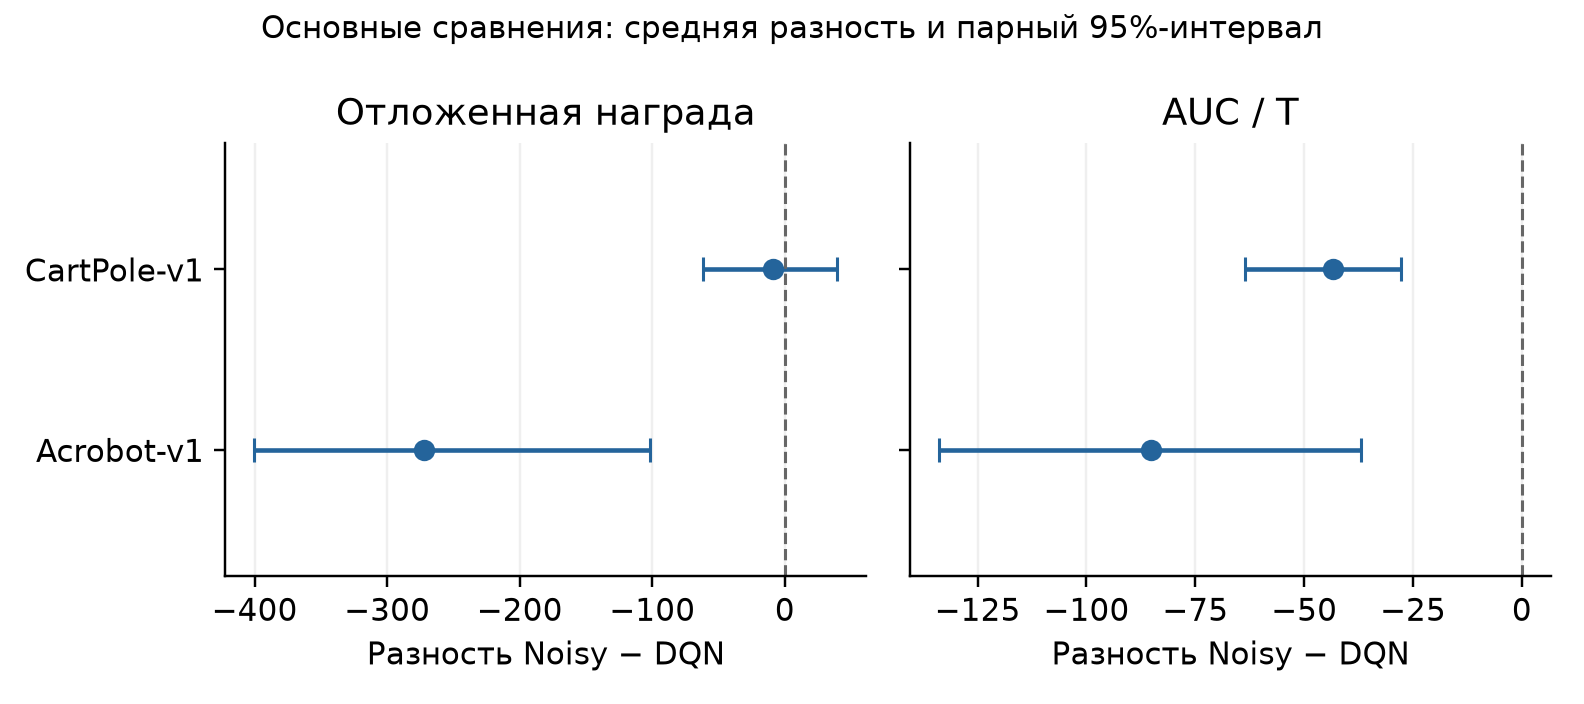

In [5]:
comparisons = pd.DataFrame(summary["comparisons_vs_dqn"])
primary = comparisons.loc[comparisons.comparison_type == "primary"]
display(primary[["environment", "metric", "mean_difference", "ci95_low", "ci95_high", "n_pairs"]]
        .rename(columns={"environment": "Среда", "metric": "Метрика",
                         "mean_difference": "Noisy − DQN", "ci95_low": "Нижняя граница 95%",
                         "ci95_high": "Верхняя граница 95%", "n_pairs": "Пар seed"})
        .reset_index(drop=True))
make_study_figures(runs, curves, summary, OUTPUT / "figures")
display(Image(filename=str(OUTPUT / "figures/main_differences.png")))

На кривых показано среднее по десяти seed; полоса — одно стандартное отклонение между seed. Полоса не является доверительным интервалом. Границы среднего ± SD могут выходить за диапазон возможных наград; пунктир −500 отмечает минимальную награду Acrobot. Оси сохраняют всю полосу разброса.

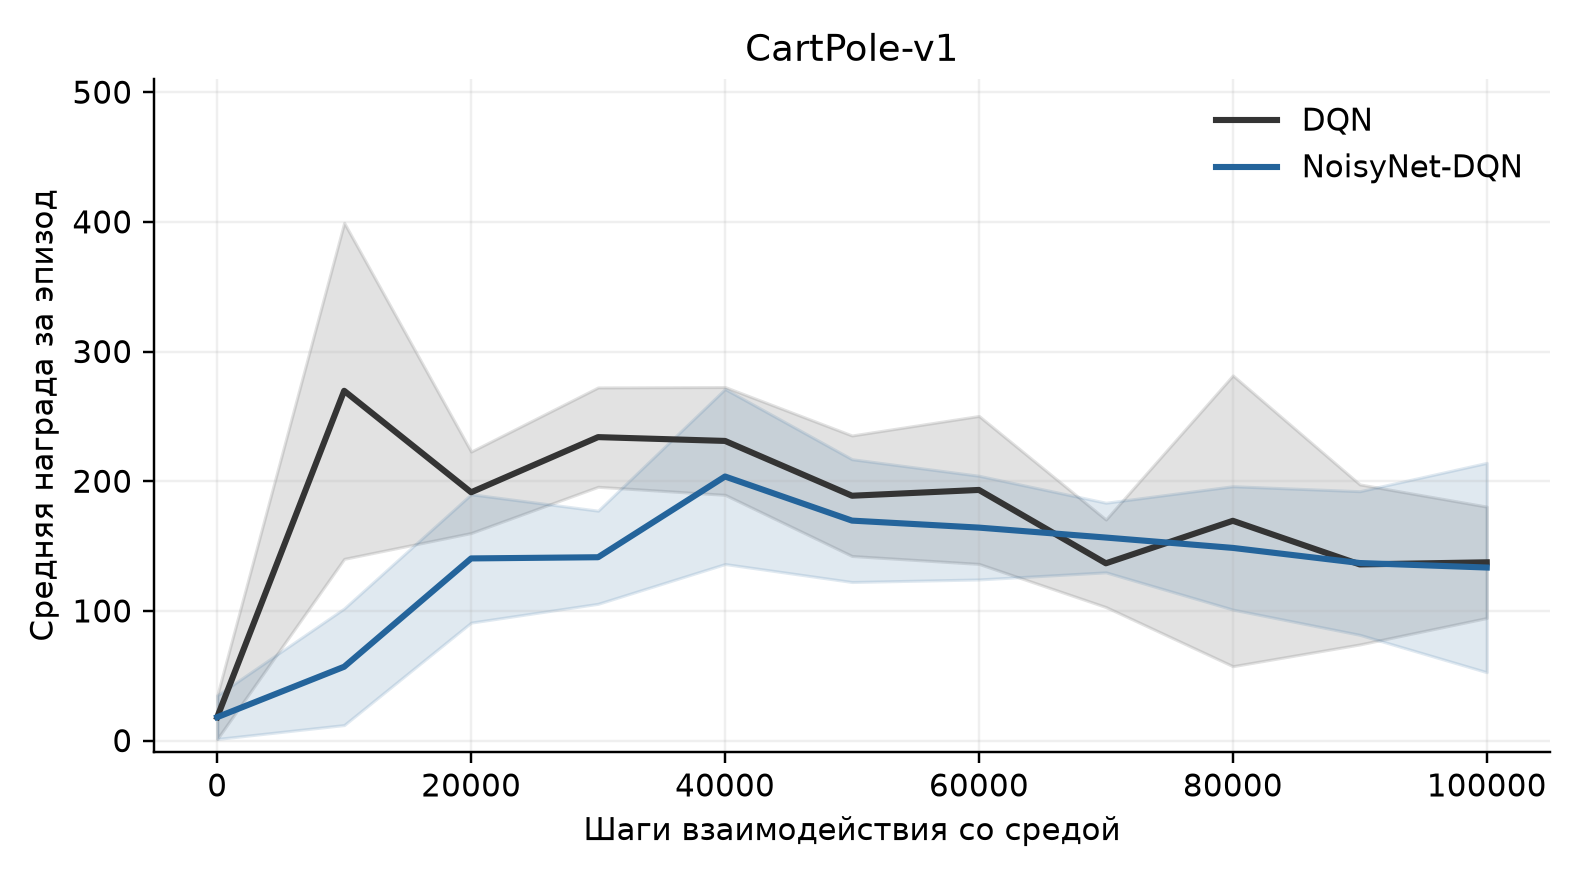

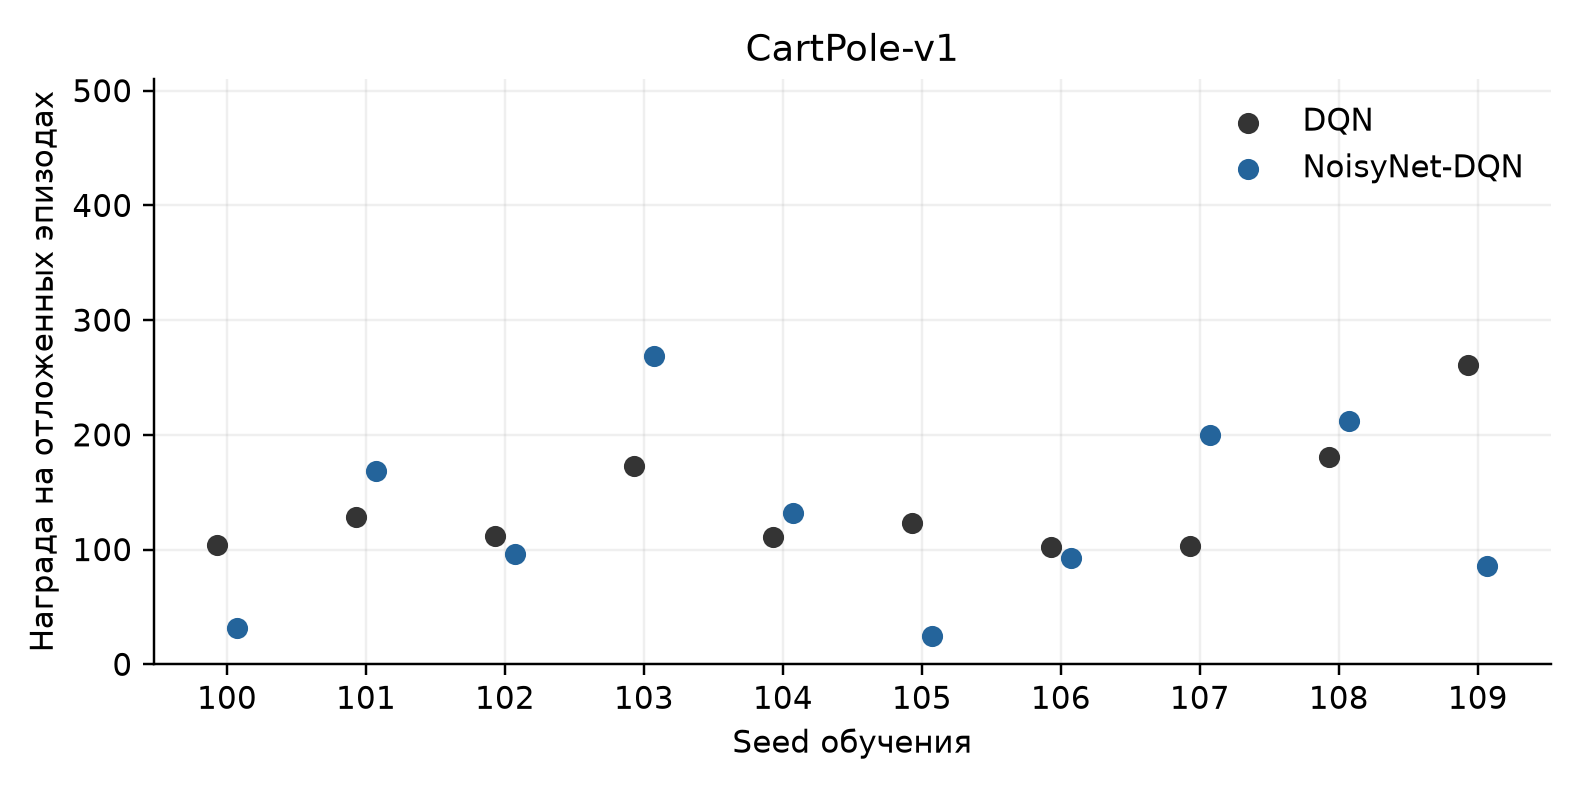

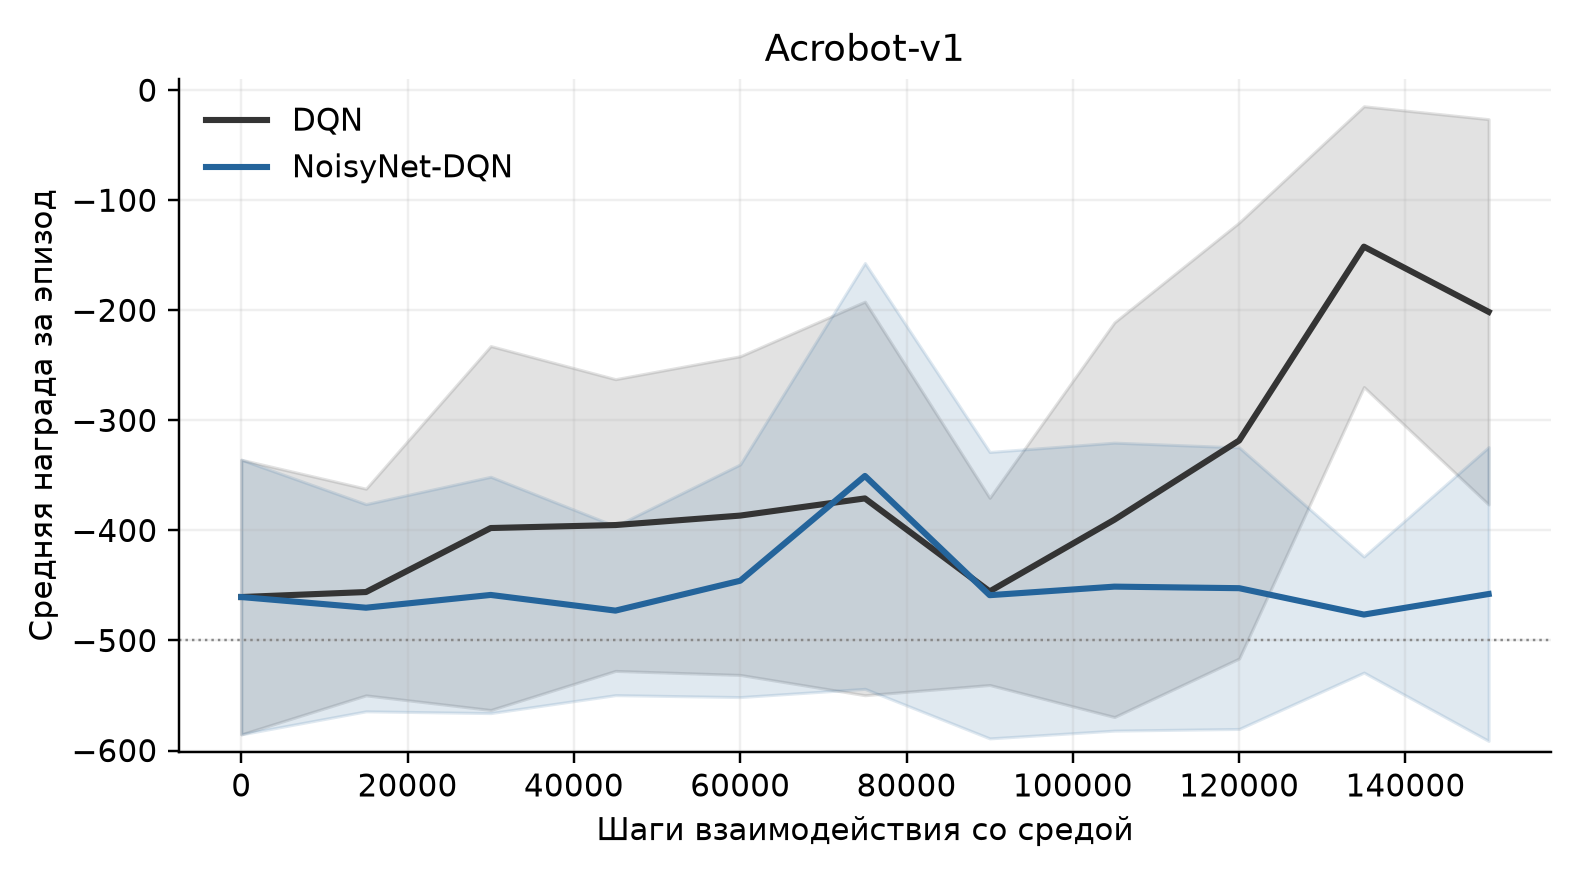

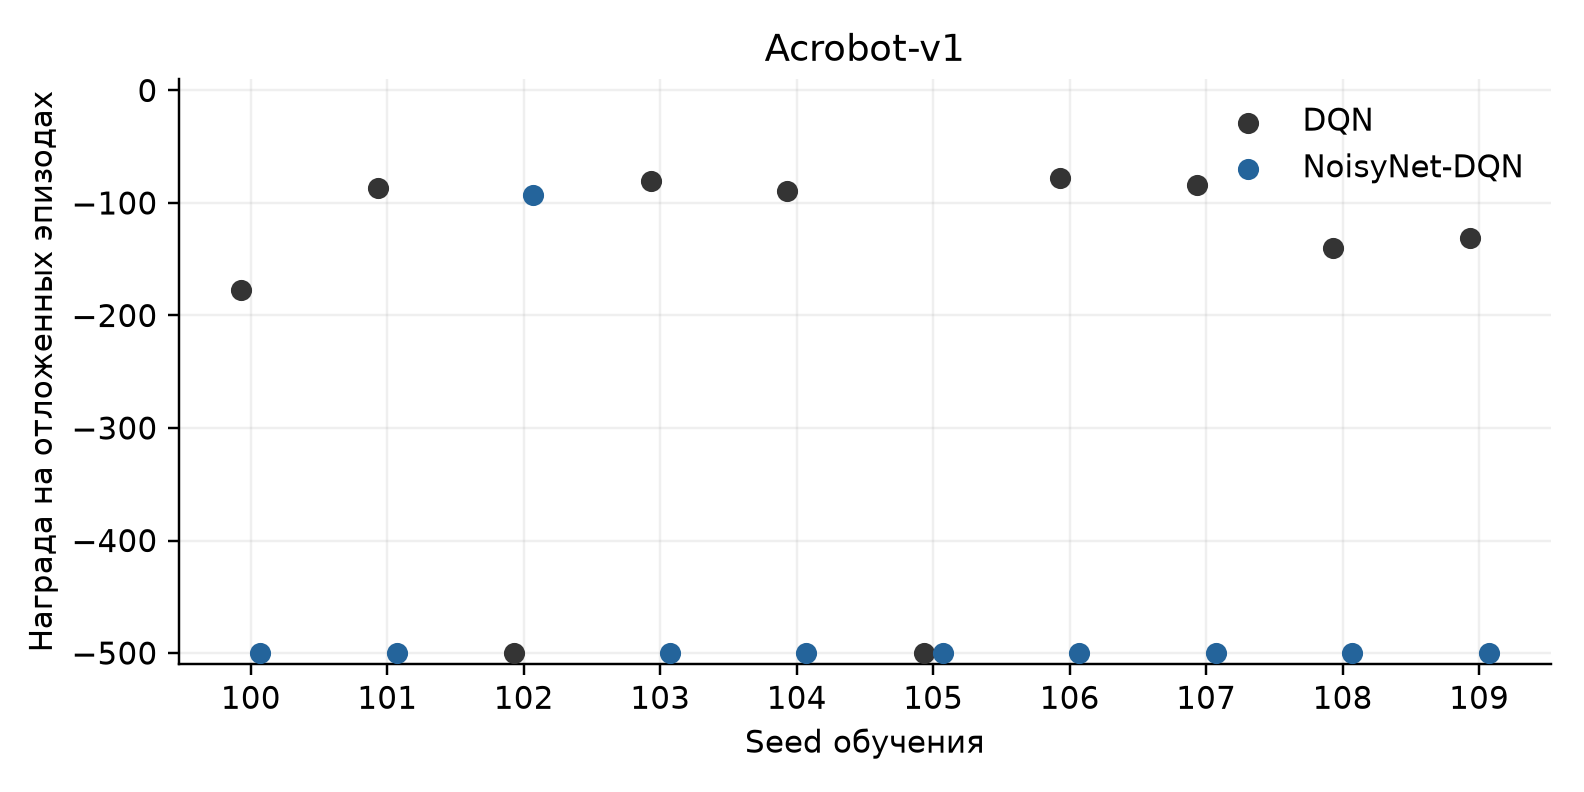

In [6]:
for environment in ["cartpole", "acrobot"]:
    display(Image(filename=str(OUTPUT / "figures" / f"{environment}_learning.png")))
    display(Image(filename=str(OUTPUT / "figures" / f"{environment}_final_by_seed.png")))

## 5. Абляции на Acrobot

,Условие,Метрика,Вариант − основной Noisy,Нижняя граница 95%,Верхняя граница 95%
0,noisy_sigma01,final_mean,30.323,-36.557,122.953
1,noisy_sigma01,auc_mean,9.709,-19.414,37.085
2,noisy_sigma10,final_mean,54.277,-1.740,142.663
3,noisy_sigma10,auc_mean,-4.099,-31.044,21.151
4,noisy_fixed,final_mean,-40.727,-122.180,0.000
5,noisy_fixed,auc_mean,-41.902,-68.066,-17.477
6,noisy_update,final_mean,27.523,-93.237,146.863
7,noisy_update,auc_mean,28.171,-9.474,67.490


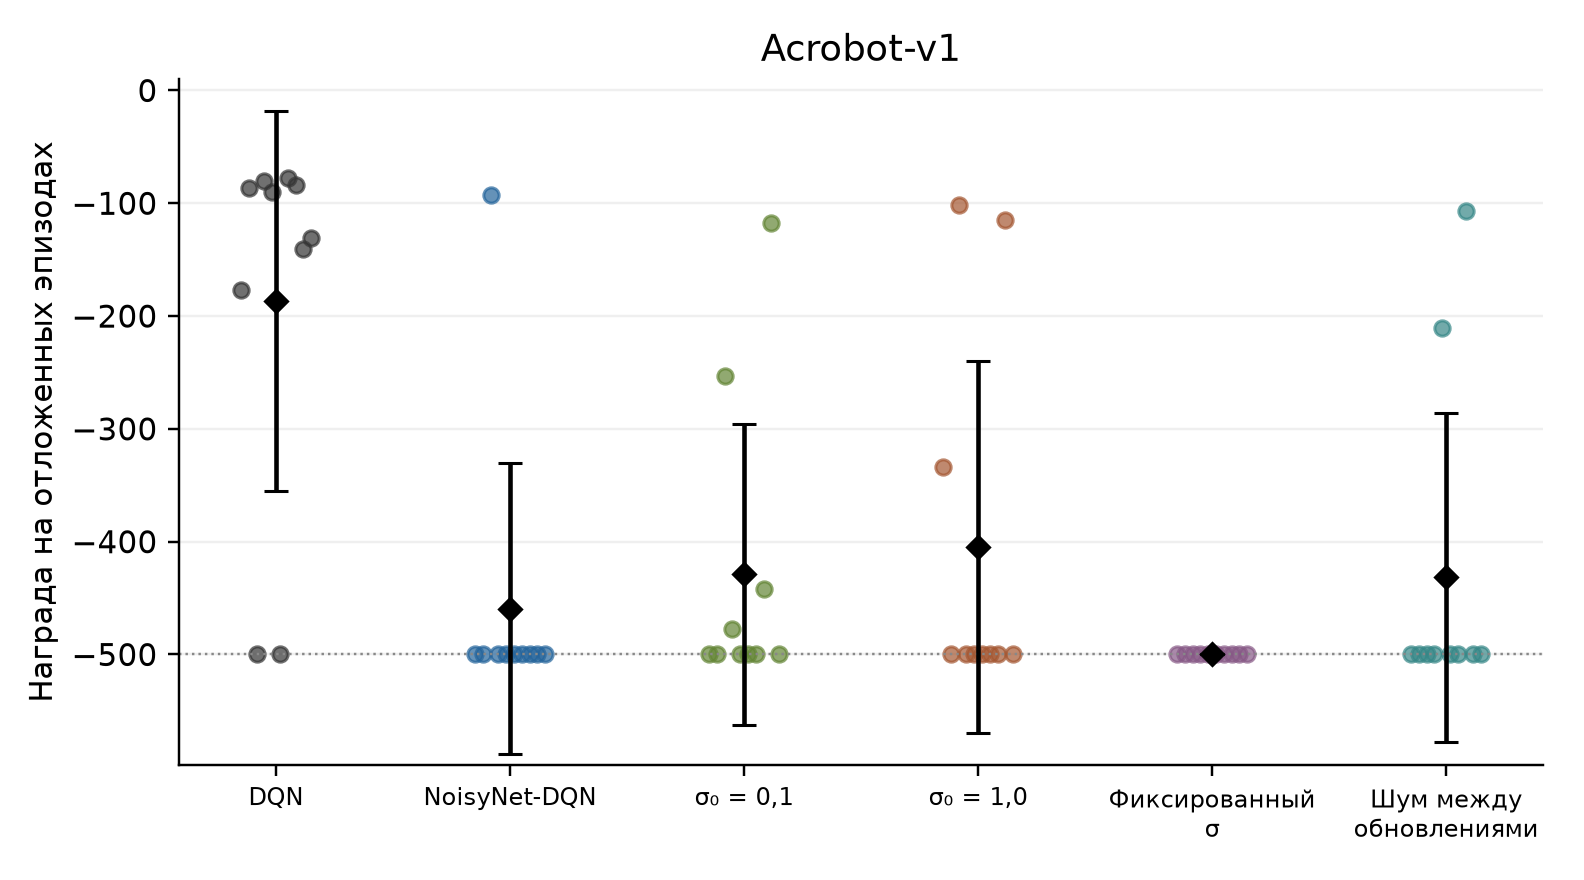

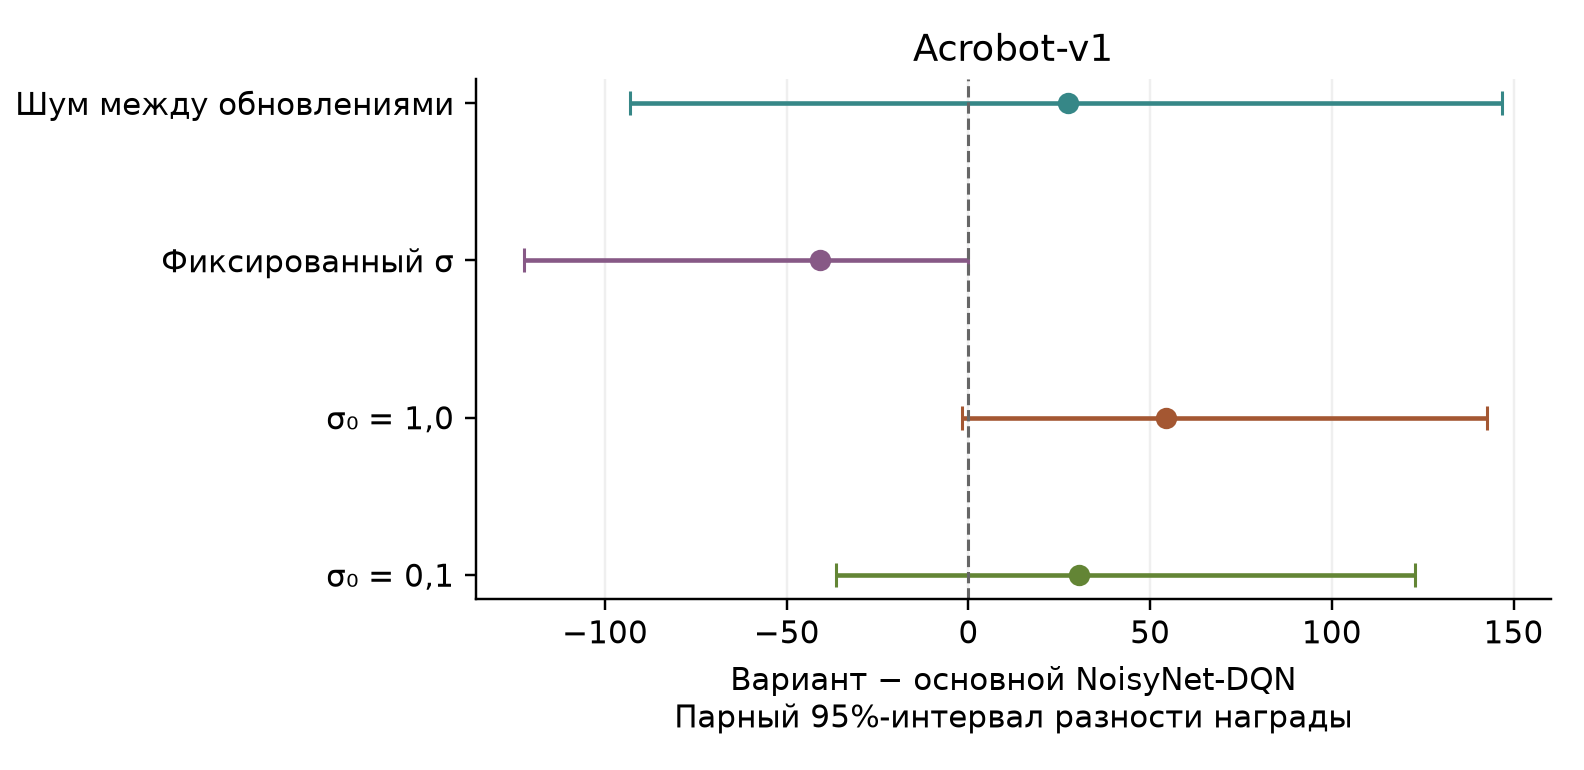

In [7]:
ablations = pd.DataFrame(summary["ablations_vs_noisy"])
display(ablations[["condition", "metric", "mean_difference", "ci95_low", "ci95_high"]]
        .rename(columns={"condition": "Условие", "metric": "Метрика",
                         "mean_difference": "Вариант − основной Noisy",
                         "ci95_low": "Нижняя граница 95%", "ci95_high": "Верхняя граница 95%"})
        .reset_index(drop=True))
display(Image(filename=str(OUTPUT / "figures/acrobot_ablations.png")))
display(Image(filename=str(OUTPUT / "figures/acrobot_ablation_differences.png")))

Точки на первом графике — отдельные seed; чёрный ромб и отрезок — среднее
и одно SD. На втором графике показаны парные 95%-интервалы разности
по сравнению с основным NoisyNet-DQN. Эти интервалы имеют разный смысл
и не должны интерпретироваться одинаково.

Абляция фиксированного σ проверяет роль его обучения при выбранной
инициализации, а не пользу любого возможного неизменного масштаба.
Два других начальных значения σ₀ не образуют исчерпывающий поиск параметра.
Абляция частоты шума относится к заданной частоте оптимизации раз в четыре
шага и не переносится автоматически на другие алгоритмы.

## 6. Масштаб шума и режим оценки

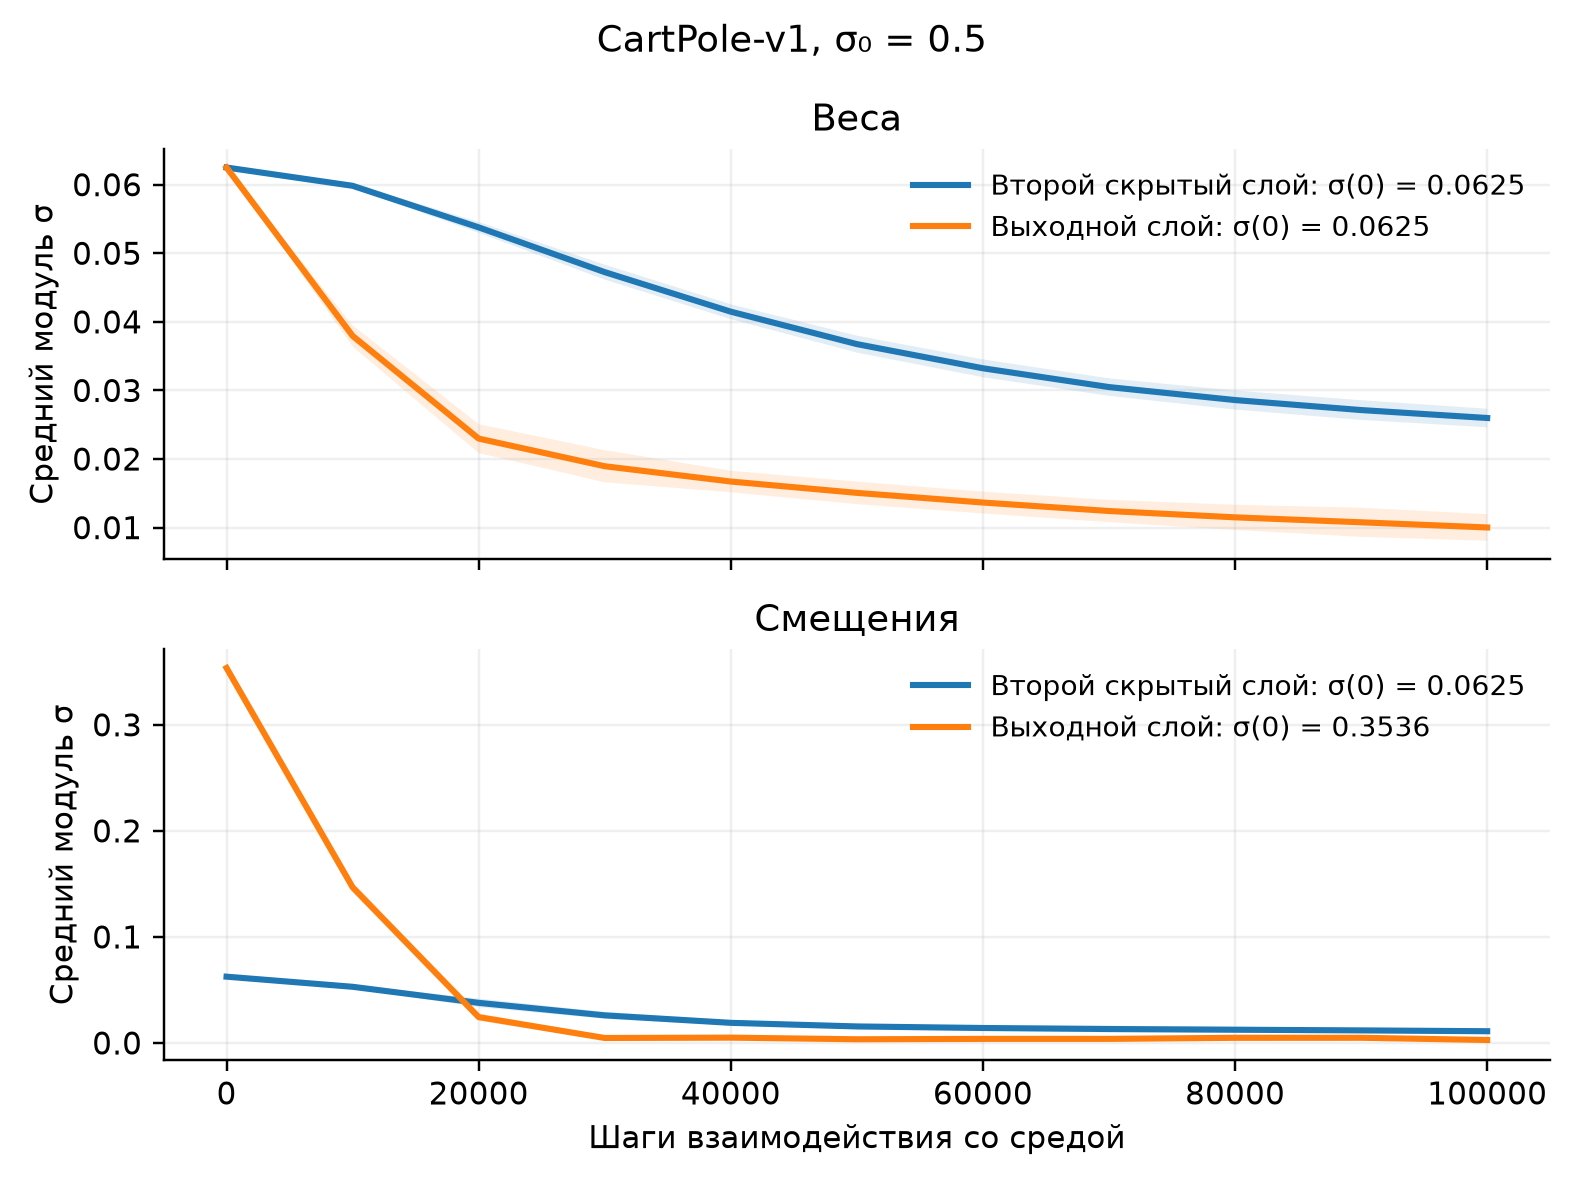

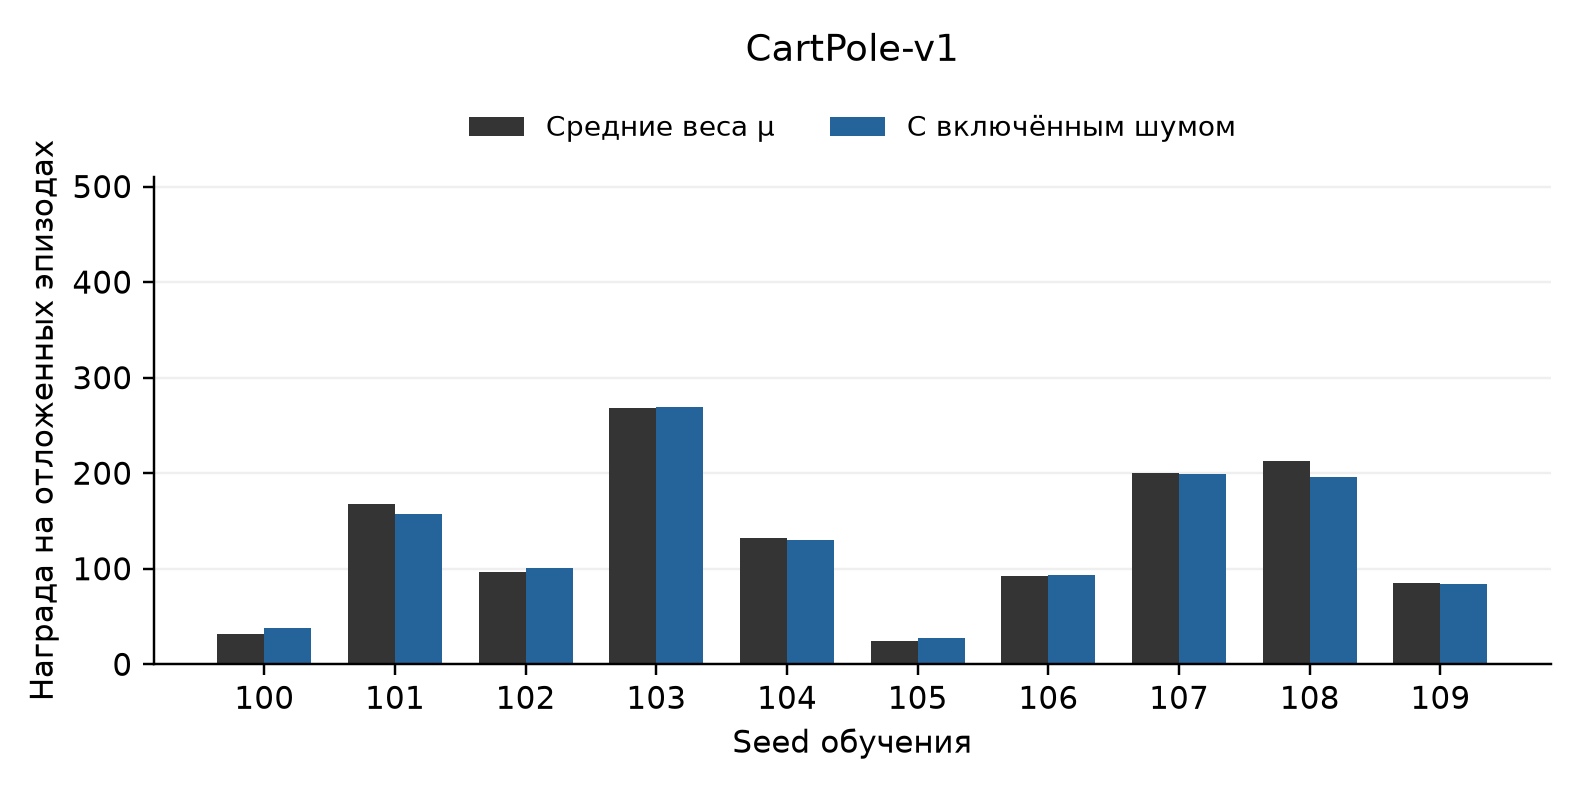

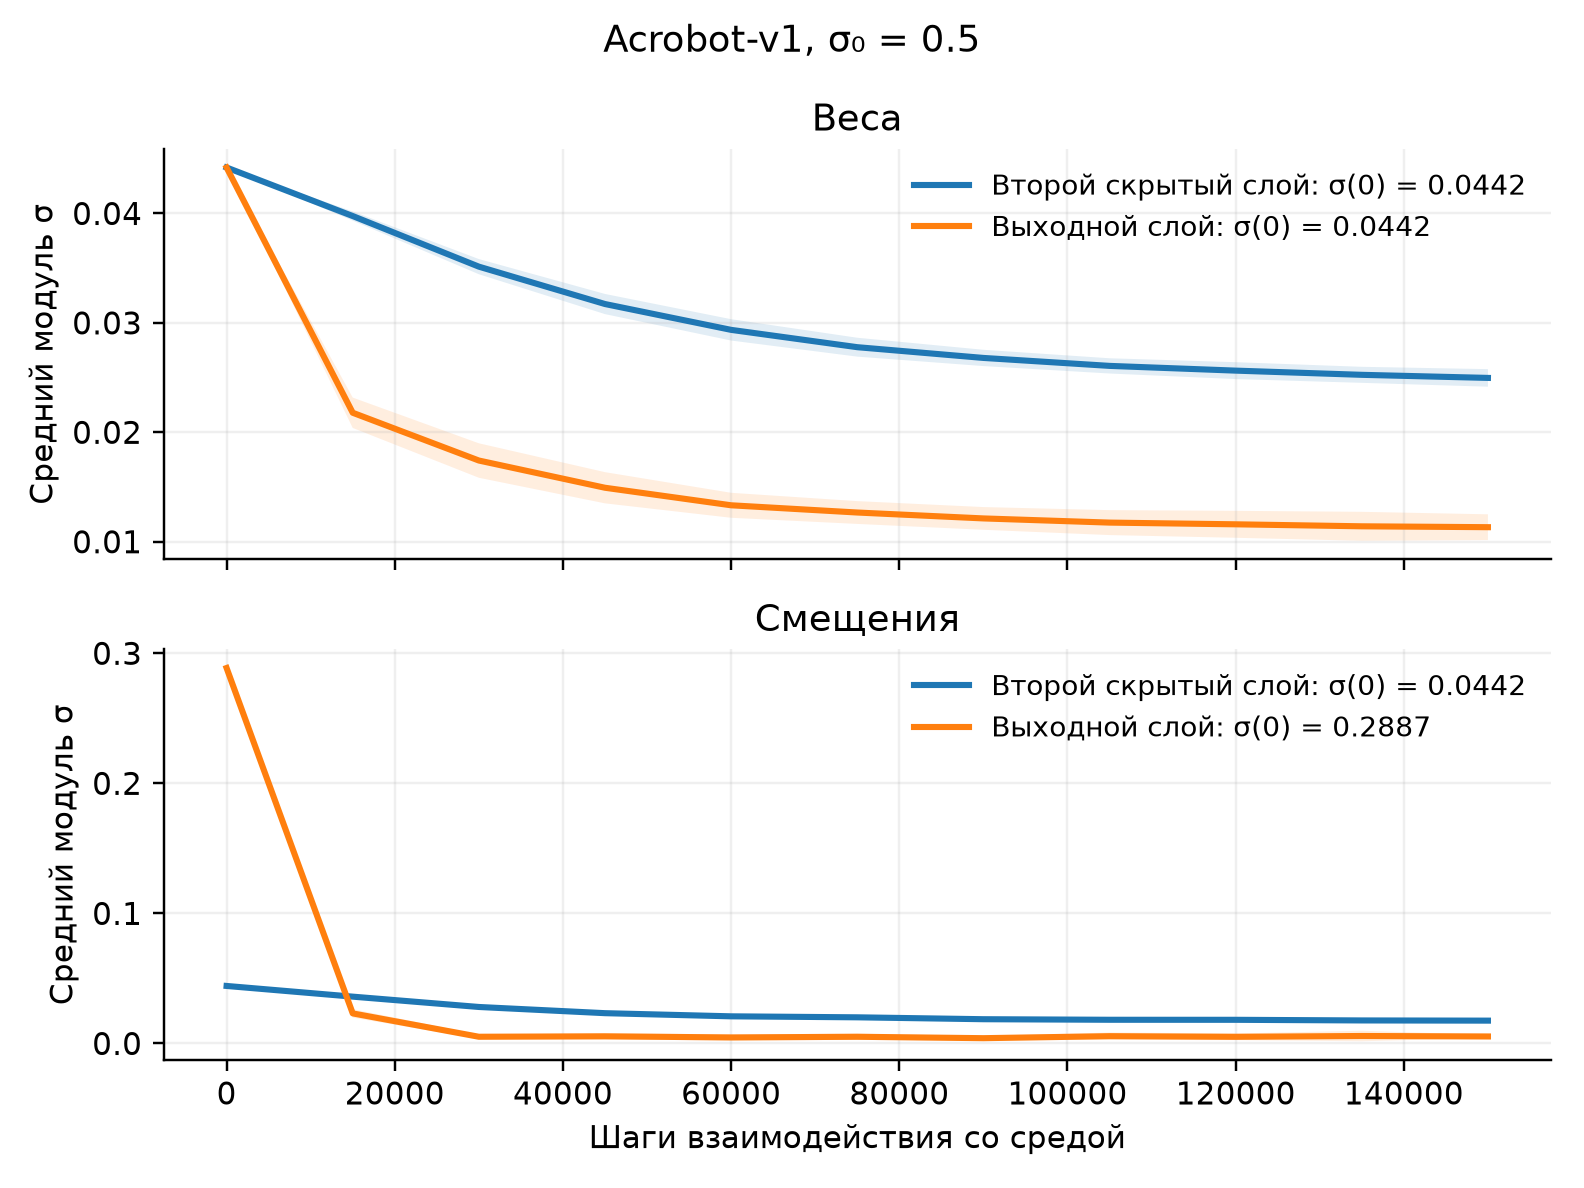

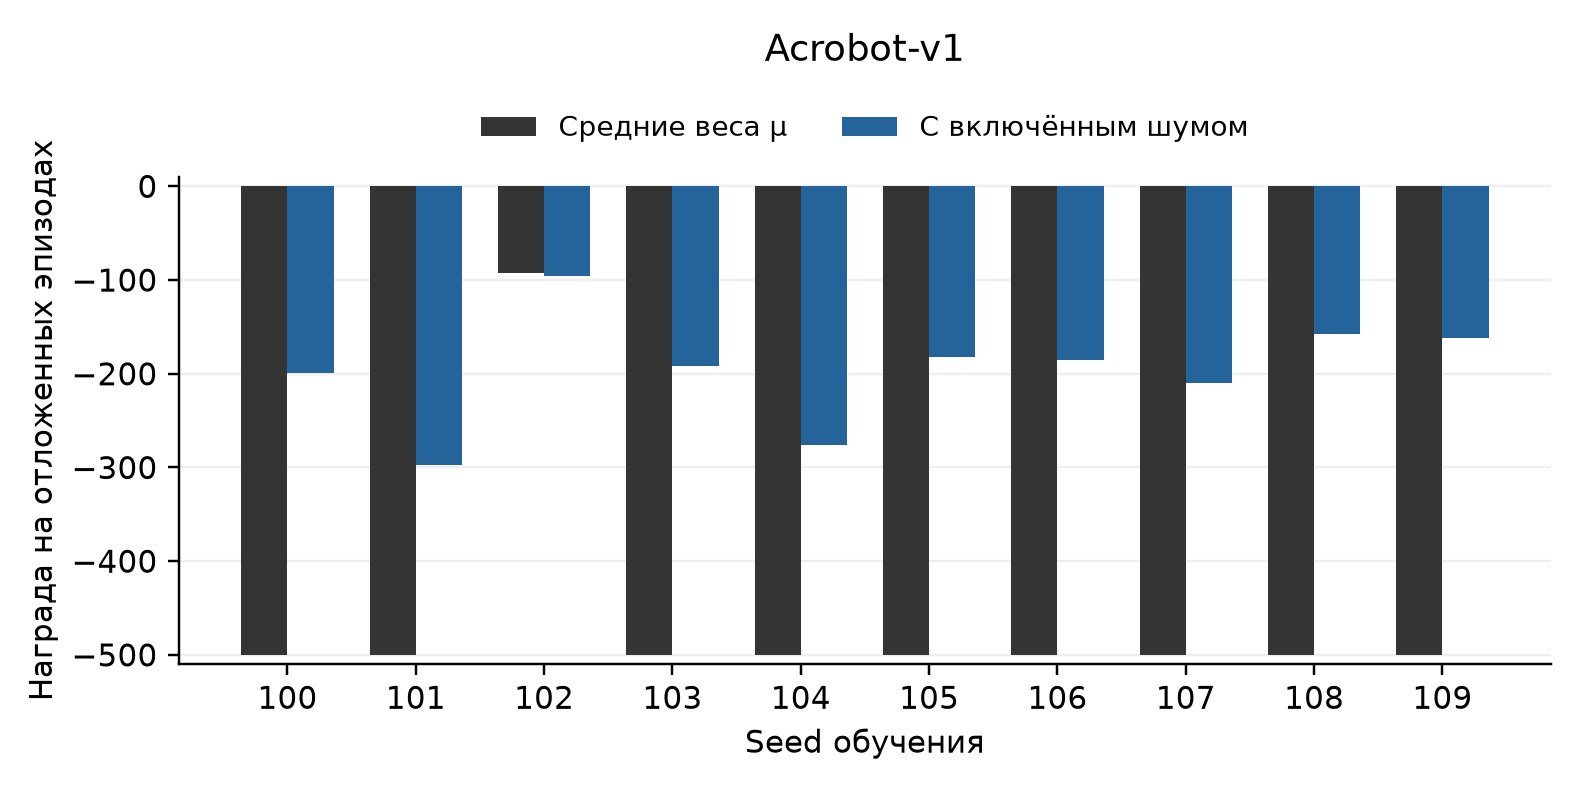

,Среда,Условие,С шумом − по μ,Нижняя граница 95%,Верхняя граница 95%
0,acrobot,noisy,263.610,195.776,313.963
1,acrobot,noisy_sigma01,235.120,141.057,312.453
2,acrobot,noisy_sigma10,213.710,119.033,297.992
3,acrobot,noisy_fixed,8.157,0.757,18.767
4,acrobot,noisy_update,266.013,181.700,331.767
5,cartpole,noisy,-1.440,-6.010,2.270


,Среда,Noisy с шумом − DQN,Нижняя граница 95%,Верхняя граница 95%
0,acrobot,-8.960,-117.781,122.274
1,cartpole,-10.187,-61.815,36.920


In [8]:
for environment in ["cartpole", "acrobot"]:
    display(Image(filename=str(OUTPUT / "figures" / f"{environment}_sigma.png")))
    display(Image(filename=str(OUTPUT / "figures" / f"{environment}_evaluation_modes.png")))
mode_table = pd.DataFrame(summary["evaluation_mode_differences"])
display(mode_table[["environment", "condition", "mean_difference", "ci95_low", "ci95_high"]]
        .rename(columns={"environment": "Среда", "condition": "Условие",
                         "mean_difference": "С шумом − по μ", "ci95_low": "Нижняя граница 95%",
                         "ci95_high": "Верхняя граница 95%"}).reset_index(drop=True))
stochastic_comparisons = pd.DataFrame(summary["stochastic_vs_dqn"])
display(stochastic_comparisons[["environment", "mean_difference", "ci95_low", "ci95_high"]]
        .rename(columns={"environment": "Среда", "mean_difference": "Noisy с шумом − DQN",
                         "ci95_low": "Нижняя граница 95%", "ci95_high": "Верхняя граница 95%"})
        .reset_index(drop=True))

Две панели графика σ показывают средний модуль обучаемых масштабов весов
и смещений каждого шумового слоя, затем среднее и SD по seed. Начальные
значения в легенде вычислены из σ₀ и размеров слоя. В исходных CSV эти
величины сохранены как `sigma_abs_*` и `bias_sigma_abs_*`. Один агрегат по слою не описывает
всю структуру шума и не измеряет непосредственно разнообразие действий.

Стохастическая оценка использует те же 30 начальных состояний и один
фиксированный seed генератора шума. Её отличие от оценки по μ описывает
эти два режима инференса; оно не устанавливает, какой режим лучше
на произвольной последовательности шумов.

Сравнение основного стохастического Noisy с жадным DQN в последней таблице
выделено **после просмотра результатов**. Это дополнительный описательный
анализ с парными интервалами без поправки на множественные сравнения;
он не заменяет заранее заданную основную оценку по μ.

## 7. Проверка сохранённых моделей и результатов

In [9]:
# Повторно проходим все отложенные эпизоды на CPU, включая шумовой режим.
verification = verify_checkpoints(RESULTS)
expected_checks = len(runs) + int((runs.algorithm != "dqn").sum())
assert len(verification) == expected_checks and verification.matches.all()
verification.to_csv(OUTPUT / "checkpoint_verification.csv", index=False)
display(verification.groupby(["environment", "mode"], as_index=False).agg(
    моделей=("matches", "size"), эпизодов=("n_episodes", "sum"),
    все_награды_и_признаки_совпали=("matches", "all")))
print(f"Повторно проверено {len(runs)} checkpoint; {verification.n_episodes.sum()} эпизодов.")

,environment,mode,моделей,эпизодов,все_награды_и_признаки_совпали
0,acrobot,mean_weights,60,1800,True
1,acrobot,resampled_noise,50,1500,True
2,cartpole,mean_weights,20,600,True
3,cartpole,resampled_noise,10,300,True


Повторно проверено 80 checkpoint; 4200 эпизодов.


Повторная оценка сравнивает все награды эпизодов, длины, seed и признаки
завершения с сохранёнными JSON. Конфигурация внутри checkpoint также
сверяется с конфигурацией запуска. При любом расхождении выполнение
останавливается. Обучение проверяется отдельно тестами проекта; эта ячейка
подтверждает воспроизводимость оценки уже обученных моделей в текущем
окружении CPU. Между платформами и версиями PyTorch полное совпадение
не гарантируется: см. [документацию PyTorch](https://docs.pytorch.org/docs/stable/notes/randomness.html).

## 8. Выводы по выполненной серии

In [10]:
conclusions = []
for environment in ["cartpole", "acrobot"]:
    data = condition_table.loc[condition_table.environment == environment].set_index("condition")
    comparison = primary.loc[(primary.environment == environment) & (primary.metric == "final_mean")].iloc[0]
    dqn, noisy = data.loc["dqn"], data.loc["noisy"]
    conclusions.append(
        f"**{dqn.env_id}.** DQN: {dqn.final_mean:.2f} ± {dqn.final_seed_sd:.2f}; "
        f"NoisyNet-DQN: {noisy.final_mean:.2f} ± {noisy.final_seed_sd:.2f} "
        f"(среднее ± SD по seed). Разность Noisy − DQN: {comparison.mean_difference:.2f}; "
        f"описательный 95%-интервал [{comparison.ci95_low:.2f}; {comparison.ci95_high:.2f}]. "
        f"AUC/T: {dqn.auc_mean:.2f} у DQN и {noisy.auc_mean:.2f} у NoisyNet-DQN."
    )
    secondary = stochastic_comparisons.loc[stochastic_comparisons.environment == environment].iloc[0]
    conclusions.append(
        f"NoisyNet-DQN с шумом: {noisy.stochastic_mean:.2f} ± {noisy.stochastic_seed_sd:.2f}. "
        f"В дополнительном сравнении с DQN разность составляет {secondary.mean_difference:.2f}; "
        f"описательный 95%-интервал [{secondary.ci95_low:.2f}; {secondary.ci95_high:.2f}]."
    )
for record in summary["ablations_vs_noisy"]:
    if record["metric"] == "final_mean":
        conclusions.append(
            f"**Acrobot, {LABELS[record['condition']]}.** Разность относительно основного Noisy: "
            f"{record['mean_difference']:.2f}, описательный 95%-интервал "
            f"[{record['ci95_low']:.2f}; {record['ci95_high']:.2f}]."
        )
display(Markdown("\n\n".join(conclusions)))

**CartPole-v1.** DQN: 139.88 ± 51.07; NoisyNet-DQN: 131.14 ± 80.04 (среднее ± SD по seed). Разность Noisy − DQN: -8.75; описательный 95%-интервал [-61.87; 39.51]. AUC/T: 182.82 у DQN и 139.42 у NoisyNet-DQN.

NoisyNet-DQN с шумом: 129.70 ± 76.42. В дополнительном сравнении с DQN разность составляет -10.19; описательный 95%-интервал [-61.82; 36.92].

**Acrobot-v1.** DQN: -186.70 ± 168.24; NoisyNet-DQN: -459.27 ± 128.79 (среднее ± SD по seed). Разность Noisy − DQN: -272.57; описательный 95%-интервал [-400.07; -101.45]. AUC/T: -364.35 у DQN и -449.60 у NoisyNet-DQN.

NoisyNet-DQN с шумом: -195.66 ± 57.72. В дополнительном сравнении с DQN разность составляет -8.96; описательный 95%-интервал [-117.78; 122.27].

**Acrobot, σ₀ = 0,1.** Разность относительно основного Noisy: 30.32, описательный 95%-интервал [-36.56; 122.95].

**Acrobot, σ₀ = 1,0.** Разность относительно основного Noisy: 54.28, описательный 95%-интервал [-1.74; 142.66].

**Acrobot, Фиксированный σ.** Разность относительно основного Noisy: -40.73, описательный 95%-интервал [-122.18; 0.00].

**Acrobot, Шум между обновлениями.** Разность относительно основного Noisy: 27.52, описательный 95%-интервал [-93.24; 146.86].

Плохой результат политики по μ на Acrobot не означает отсутствия
обученной стохастической политики. У тех же моделей включение шума
существенно меняет поведение и награду. Оценка по средним весам
не является усреднением результатов всех шумовых реализаций.

Результат относится к двум средам classic control, выбранной архитектуре,
десяти seed и фиксированному бюджету взаимодействий. Разница может
зависеть от learning rate, масштаба шума, частоты обновления и критерия
оценки. Основной режим по средним весам способен скрывать как пользу,
так и вред стохастической политики, поэтому оба режима приведены отдельно.
Нельзя по этой серии сделать общий вывод о превосходстве NoisyNets
в обучении с подкреплением или об эквивалентности методов.

Время `elapsed_seconds` в исходных данных включает обучение, оценочные
эпизоды и запись файлов; серия запускалась параллельно. Оно не является
чистым временем шага алгоритма и не используется для вывода о вычислительной
эффективности. Анализ дополнительных сред, большего числа seed и набора
независимых оценочных стартов остаётся направлением продолжения работы.

In [11]:
runs.to_csv(OUTPUT / "per_run.csv", index=False)
curves.to_csv(OUTPUT / "curves.csv", index=False)
condition_table.to_csv(OUTPUT / "conditions.csv", index=False)
comparisons.to_csv(OUTPUT / "comparisons.csv", index=False)
ablations.to_csv(OUTPUT / "ablations.csv", index=False)
stochastic_comparisons.to_csv(OUTPUT / "stochastic_comparisons.csv", index=False)
(OUTPUT / "summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print("Сводные данные: results/final_analysis; графики: results/final_analysis/figures.")

Сводные данные: results/final_analysis; графики: results/final_analysis/figures.


## Источники

1. Fortunato M. et al. [Noisy Networks for Exploration](https://arxiv.org/abs/1706.10295). ICLR, 2018.
2. Mnih V. et al. [Playing Atari with Deep Reinforcement Learning](https://arxiv.org/abs/1312.5602). 2013.
3. Agarwal R. et al. [Deep Reinforcement Learning at the Edge of the Statistical Precipice](https://arxiv.org/abs/2108.13264). NeurIPS, 2021.
4. Farama Foundation. [CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/), [Acrobot](https://gymnasium.farama.org/environments/classic_control/acrobot/), [Handling Time Limits](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/).
5. PyTorch. [Reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html); TorchRL. [Исходный код NoisyLinear](https://docs.pytorch.org/rl/stable/_modules/torchrl/modules/models/exploration.html).

Все ссылки ведут на статьи авторов или официальную документацию.